# Defense Evidence - Minh chứng vấn đáp

Notebook này là trang tổng quan. Khi cần đi sâu, mở [Dataset & DSP](01_Dataset_DSP_Evidence.ipynb), [Model & Quantization](02_Model_Selection_Quantization.ipynb), [Embedded & System](03_Embedded_System_Evidence.ipynb) hoặc [Why / Why not](04_Why_Not_Tradeoffs.ipynb).

| Câu hỏi | Minh chứng chính | Nội dung khi trình bày |
|---|---|---|
| Q01 | Dataset Split | Core theo Patient ID, Playback theo WAV nguồn, Environment theo Session ID |
| Q03 | DSP Pipeline | PCM16 → Butterworth → STFT/Mel → Log-Mel `40×129×1` |
| Q14 | QAT Comparison | Đối chiếu FP32, PTQ và QAT; không khẳng định INT8 luôn tốt hơn |
| Q21 | CHECK FSM | CHECK → Quality → DSP → TinyML → Vitals → ESP-NOW |
| Q25 | TinyML Deployment | Model Flash, Tensor Arena, `AllocateTensors`, Invoke và parity |
| Q36 | ESP-NOW Packet | Callback → Queue → AES-GCM → payload → ACK/NACK |
| Q44 | Wi-Fi/LTE Failover | Wi-Fi mất 15 s → thử LTE → đổi uplink → reconnect MQTT |
| Q50 | MQTT Connection | Gateway JSON → MQTT → state model → QML widgets |
| Q54 | System Workflow | Node vẫn xử lý local khi mất Gateway; chưa có hàng đợi bền vững |

In [13]:
from pathlib import Path
from html import escape
import json
import re

import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown, HTML

def find_repo_root():
    cwd = Path.cwd().resolve()
    for root in (cwd, *cwd.parents):
        if (root / 'Defense_Package').is_dir() and (root / 'Final_Project_NCKH').is_dir():
            return root
    raise FileNotFoundError('Không tìm thấy repository root chứa Defense_Package.')

ROOT = find_repo_root()
EVIDENCE = ROOT / 'Defense_Package' / '02_Defense_Evidence'
INDEX = pd.read_csv(EVIDENCE / 'Evidence_Index.csv')

def show_images(*relative_paths, cols=2, figsize=(14, 8)):
    paths = [EVIDENCE / path for path in relative_paths]
    rows = (len(paths) + cols - 1) // cols
    fig, axes = plt.subplots(rows, cols, figsize=figsize, squeeze=False)
    for ax, path in zip(axes.flat, paths):
        ax.imshow(plt.imread(path))
        ax.set_title(path.stem.replace('_', ' '), fontsize=10, fontweight='bold')
        ax.axis('off')
    for ax in axes.flat[len(paths):]:
        ax.axis('off')
    plt.tight_layout()
    plt.show()

def render_code(text):
    payload = escape(text)
    display(HTML(
        '<pre style="margin:8px 0;padding:14px 16px;'
        'background:#f8fafc;color:#172033;border:1px solid #cbd5e1;'
        'border-radius:8px;white-space:pre-wrap;overflow-x:auto;'
        'font:13px/1.45 Consolas,Monaco,monospace;">'
        f'{payload}</pre>'
    ))

def show_log(relative_path, patterns, context=0):
    text = (EVIDENCE / relative_path).read_text(encoding='utf-8', errors='replace').splitlines()
    selected = []
    for i, line in enumerate(text):
        if any(re.search(pattern, line, re.I) for pattern in patterns):
            lo, hi = max(0, i-context), min(len(text), i+context+1)
            selected.extend(text[lo:hi])
    render_code('\n'.join(dict.fromkeys(selected)))

def show_source_matches(relative_path, patterns):
    path = ROOT / relative_path
    lines = path.read_text(encoding='utf-8', errors='replace').splitlines()
    selected = [f'{i:04d}: {line}' for i, line in enumerate(lines, 1)
                if any(re.search(pattern, line, re.I) for pattern in patterns)]
    render_code('\n'.join(selected))

print('Repository:', ROOT)
print('Evidence files:', len(INDEX))

Repository: D:\NCKH_2026\NCKH_2026_AIOT
Evidence files: 31


## Chỉ mục minh chứng

Lọc theo mã câu hỏi để biết file trình chiếu và nguồn artifact gốc.

In [14]:
display(INDEX[['evidence_id', 'question_ids', 'title', 'type', 'copied_path', 'status']])

,evidence_id,question_ids,title,type,copied_path,status
0,E01,Q01;Q59;Q60,Thành phần nhãn và nguồn dữ liệu,image,figures/01_Dataset/01_Label_Source_Composition...,available
1,E02,Q01;Q05,Sample rate theo Train Validation Test,image,figures/01_Dataset/02_Sample_Rate_Train_Val_Te...,available
2,E03,Q01;Q58;Q61,Ablation Dataset V2 và V3,image,figures/01_Dataset/03_Playback_Ablation_V2_V3.png,available
3,E04,Q03;Q06;Q62;Q63,Waveform PCM16 đại diện,image,figures/02_DSP/01_PCM16_Waveforms.png,available
4,E05,Q03;Q05;Q06;Q64;Q65,Log-Mel C4 của bốn nhóm,image,figures/02_DSP/02_LogMel_C4.png,available
5,E06,Q04;Q63,Đáp ứng Butterworth 100-2000 Hz order 5,image,figures/02_DSP/03_Butterworth_Response.png,available
6,E07,Q03;Q04,Audio trước và sau Butterworth,image,figures/02_DSP/04_Butterworth_Before_After.png,available
7,E08,Q03;Q06;Q07;Q64;Q65,So sánh Log-Mel Asthma và bệnh Non-Asthma,image,figures/02_DSP/05_C4_LogMel_Disease_Comparison...,available
8,E09,Q11;Q12;Q66;Q67,Lịch sử huấn luyện V1,image,figures/03_AI_Model/01_V1_Training_History.png,available
9,E10,Q12;Q66;Q69,Classification metrics V1,image,figures/03_AI_Model/02_V1_Test_Classification_...,available


## Q01 - Dataset Split

**Nói:** Core được chia theo bệnh nhân; Playback kế thừa split của WAV nguồn; Environment chia theo session trước khi cắt clip; augmentation chỉ sinh từ Asthma Core Train. Đây là cách hạn chế leakage.

**Chỉ vào ảnh:** thành phần nguồn/nhãn, sample rate gốc và ablation V2 có Playback so với V3 không Playback.

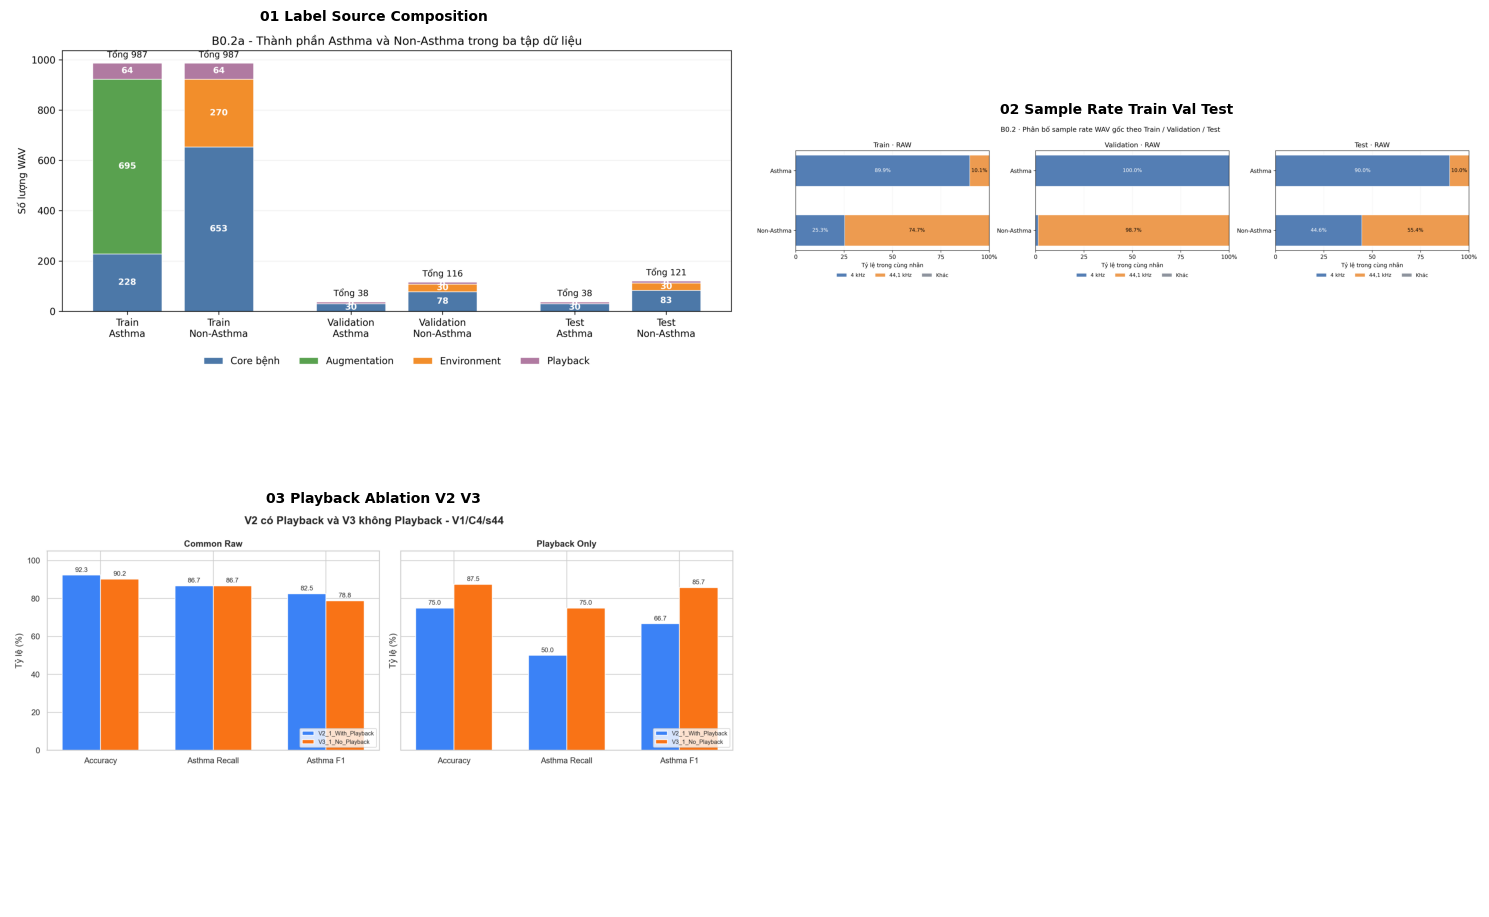

In [15]:
show_images(
    'figures/01_Dataset/01_Label_Source_Composition.png',
    'figures/01_Dataset/02_Sample_Rate_Train_Val_Test.png',
    'figures/01_Dataset/03_Playback_Ablation_V2_V3.png',
    cols=2, figsize=(15, 10),
)

## Q03 - DSP Pipeline

**Nói:** 80.000 mẫu PCM16 → mono/resample 16 kHz → cửa sổ 5 s → peak normalize → Butterworth 100–2000 Hz order 5 → STFT Hann/FFT 2048/hop 625 → 40 Mel Slaney → dB/top_db 80 → tensor `40×129×1` → min-max theo Train → INT8. C4 không dùng pre-emphasis.

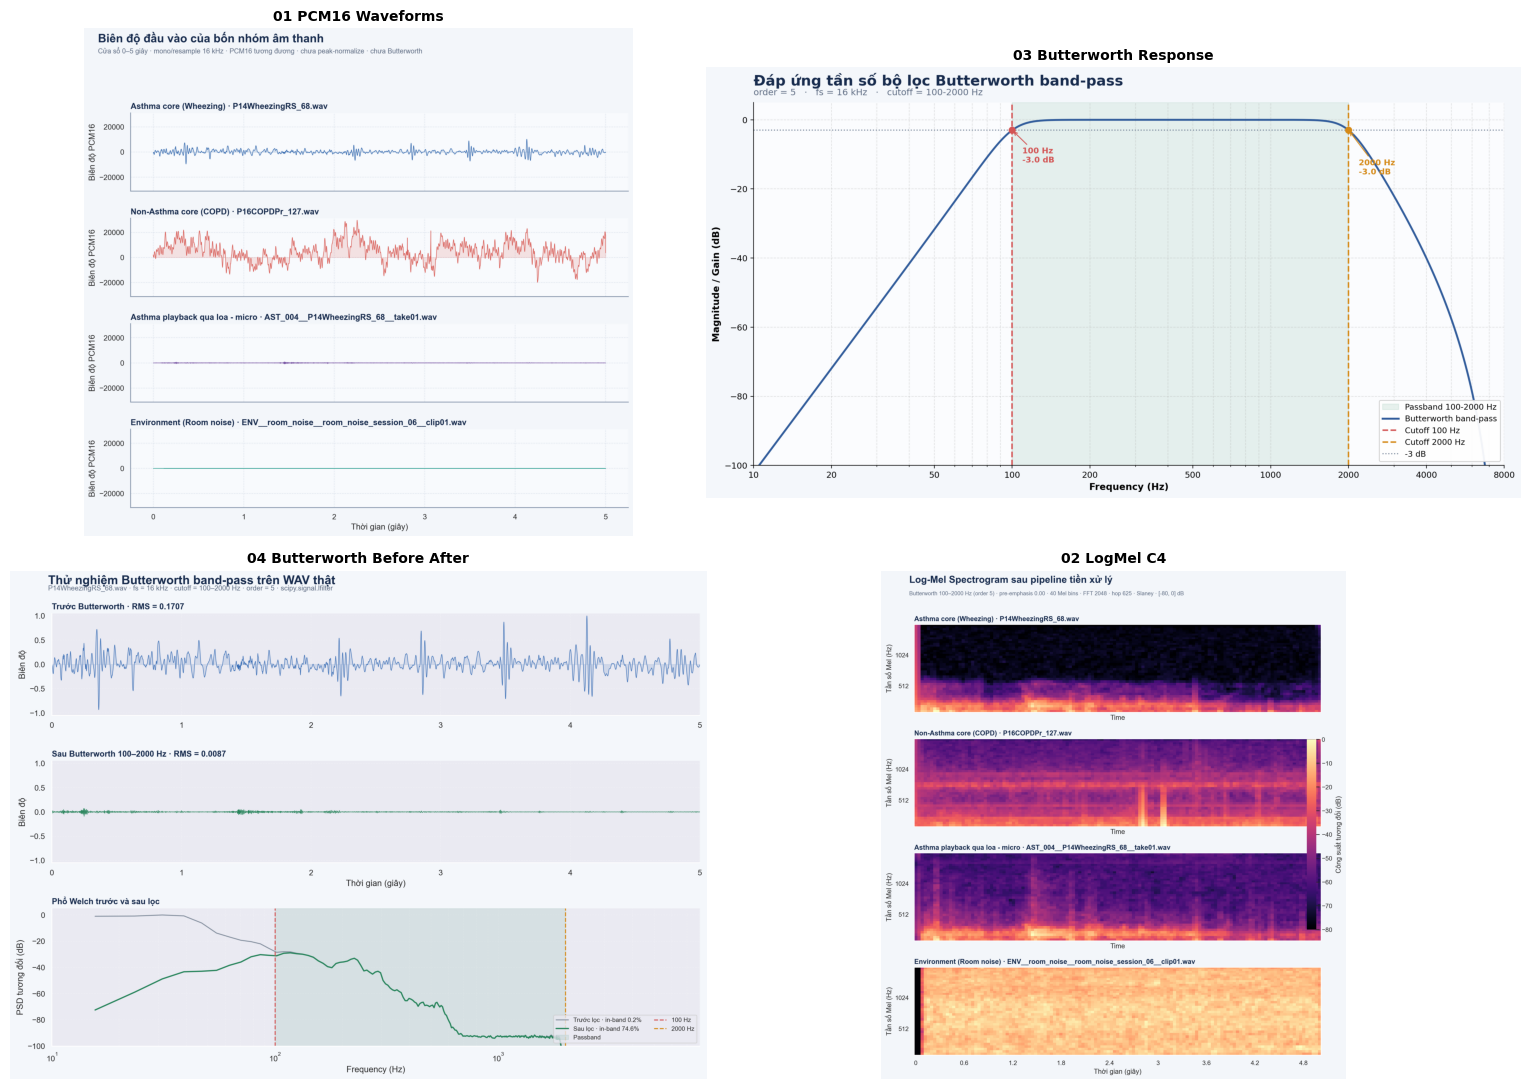

In [16]:
show_images(
    'figures/02_DSP/01_PCM16_Waveforms.png',
    'figures/02_DSP/03_Butterworth_Response.png',
    'figures/02_DSP/04_Butterworth_Before_After.png',
    'figures/02_DSP/02_LogMel_C4.png',
    cols=2, figsize=(16, 11),
)

## Q14 - FP32, PTQ và QAT

**Nói:** QAT mô phỏng hiệu ứng lượng tử trong fine-tuning để trọng số thích nghi. Kết quả QAT tốt hơn FP32 trong checkpoint được chọn là kết quả thực nghiệm, không phải quy luật chung. Chỉ cấu hình được chọn bằng Validation mới được mở Test để báo cáo cuối.

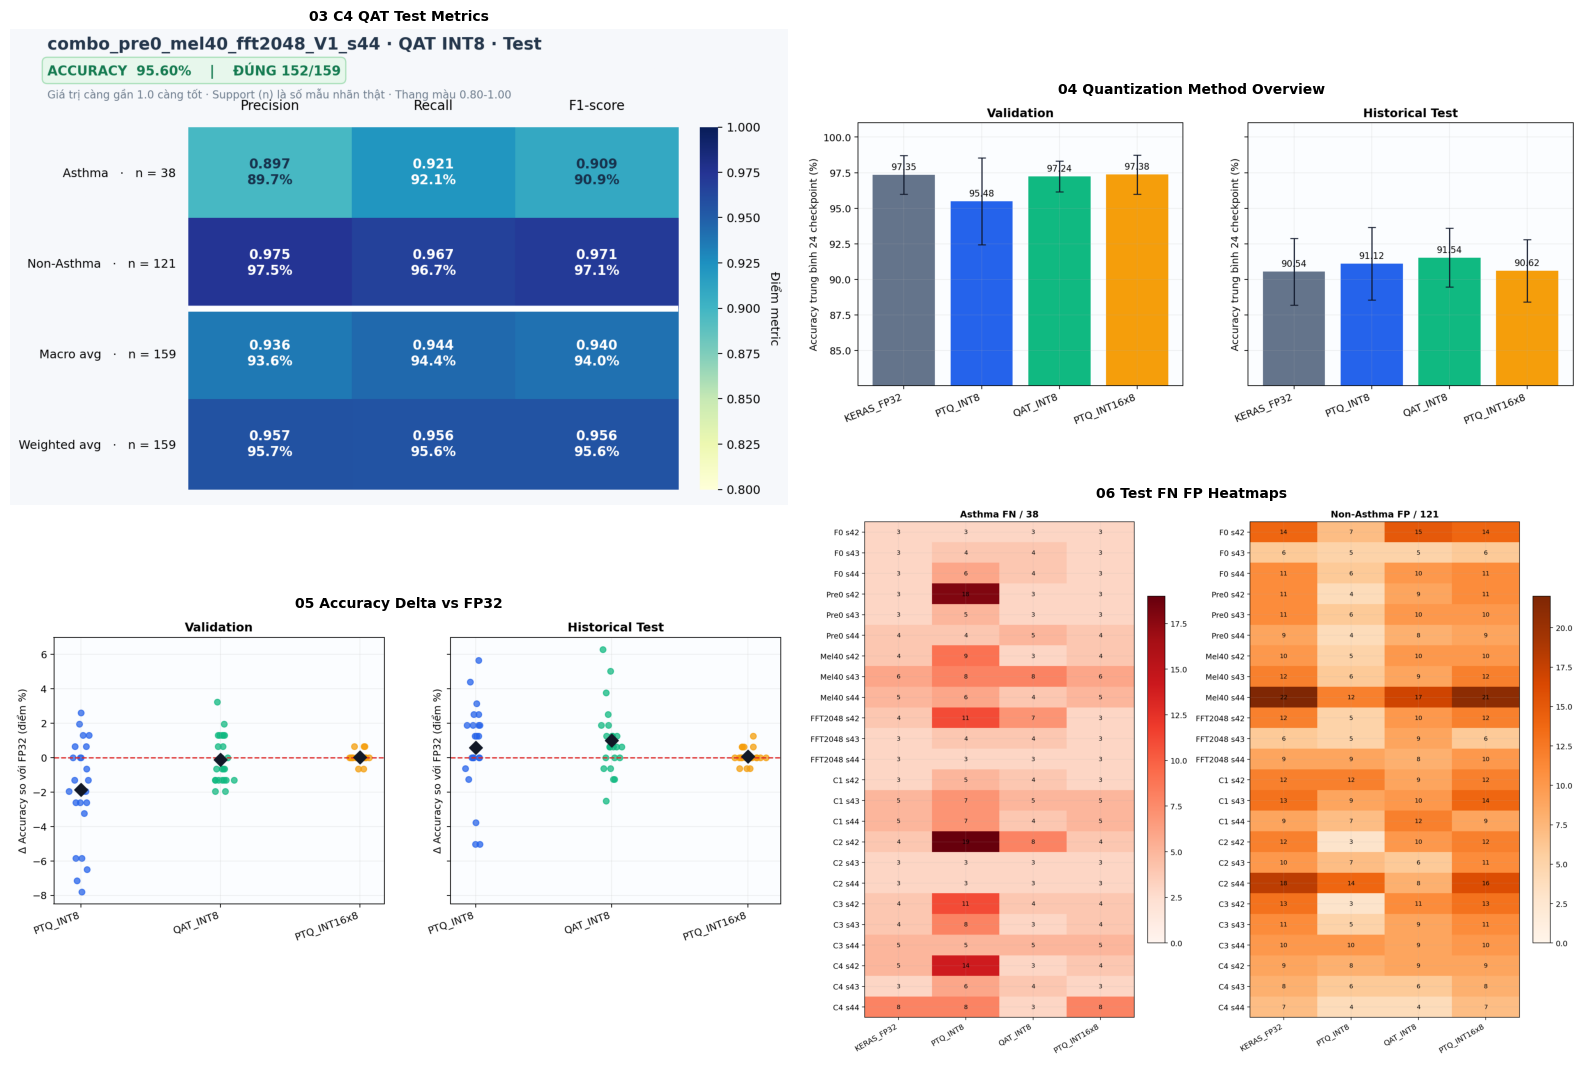

In [17]:
show_images(
    'figures/03_AI_Model/03_C4_QAT_Test_Metrics.png',
    'figures/03_AI_Model/04_Quantization_Method_Overview.png',
    'figures/03_AI_Model/05_Accuracy_Delta_vs_FP32.png',
    'figures/03_AI_Model/06_Test_FN_FP_Heatmaps.png',
    cols=2, figsize=(16, 11),
)

## Q21 - Luồng CHECK

**Nói:** CHECK → thu 5 s → Quality Gate → DSP C4 → TFLM → phân loại/OLED → đo vitals có timeout → đóng payload → AES-GCM → ESP-NOW → ACK/NACK. AI chạy cục bộ nên không phụ thuộc Internet để có kết quả.

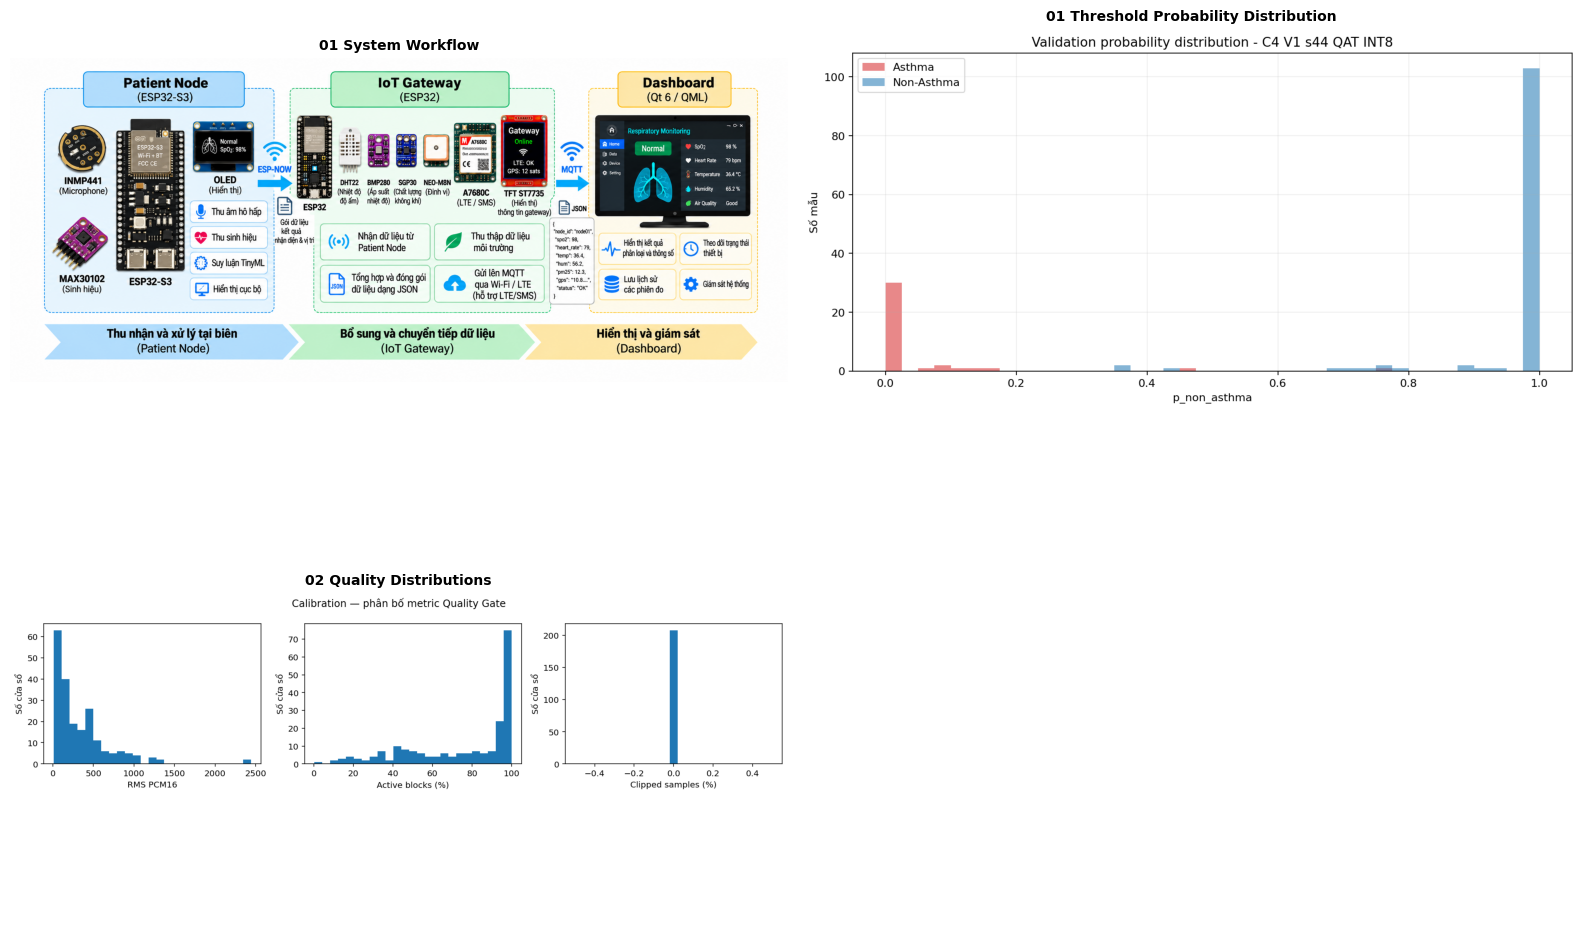

In [18]:
show_images(
    'figures/06_System/01_System_Workflow.png',
    'figures/04_Final_Validation/01_Threshold_Probability_Distribution.png',
    'figures/04_Final_Validation/02_Quality_Distributions.png',
    cols=2, figsize=(16, 10),
)

## Q25 - TinyML Deployment

**Nói từ log thật:** model QAT INT8 347.968 B; tensor input 5.160 B; arena dùng 169.380 B; `AllocateTensors()` PASS; invoke trung bình khoảng 1.164 ms; 36/36 inference thành công; Python/ESP32 cùng nhãn 12/12. Arena capacity 1 MiB trong log là vùng thử profiling, không phải lượng thực dùng.

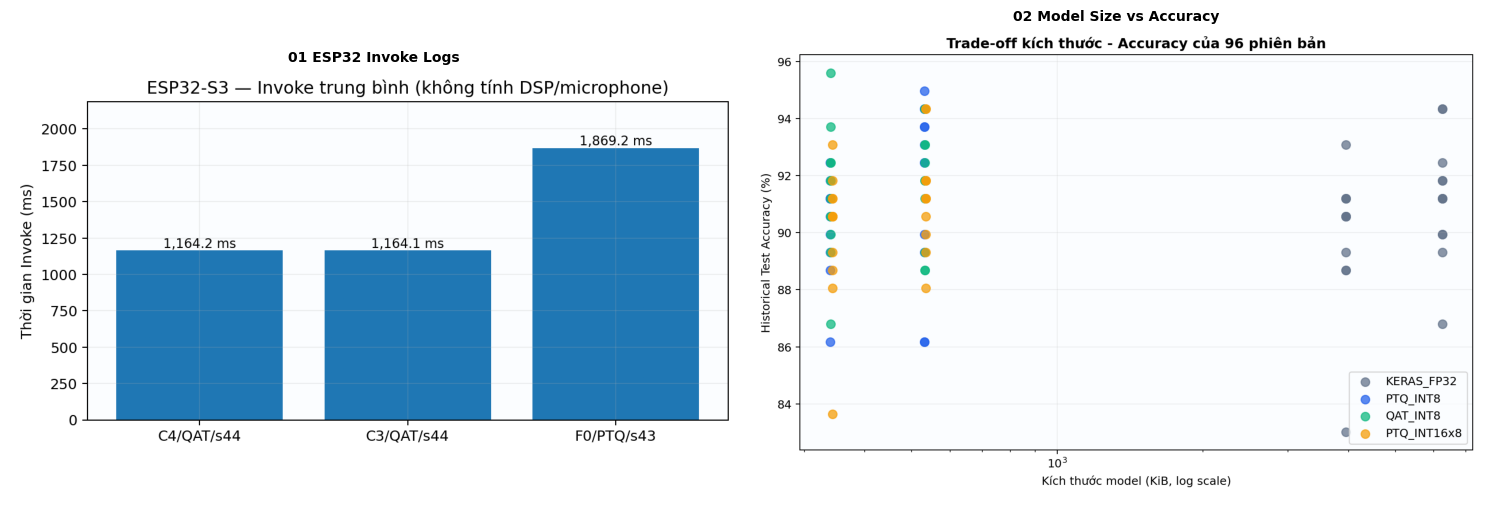

In [19]:
show_images(
    'figures/05_Deployment/01_ESP32_Invoke_Logs.png',
    'figures/05_Deployment/02_Model_Size_vs_Accuracy.png',
    cols=2, figsize=(15, 6),
)
show_log('logs/C4_QAT_ESP32_Static.log', [
    r'Active model', r'Flash model size', r'Input bytes', r'Arena used',
    r'AllocateTensors OK', r'latency avg', r'36 OK', r'label match', r'Stability',
])

## Q36 - ESP-NOW Packet

**Nói:** callback chỉ nhận/copy gói 56 byte vào Queue; TaskEspNow xử lý nặng bên ngoài callback, xác thực AES-GCM, kiểm tra payload/session/sequence, cập nhật state rồi gửi ACK/NACK. Tránh nói callback tự giải mã nếu code thực tế dùng Queue.

In [20]:
show_source_matches(
    'Final_Project_NCKH/Gateway/include/Config/gateway_config.h',
    [r'SECURE_ESPNOW_PACKET_SIZE', r'AES-128-GCM', r'KEY_NODE_TO_GATEWAY'],
)
show_source_matches(
    'Final_Project_NCKH/Gateway/src/main.cpp',
    [r'callback.*Queue', r'RX path ready', r'TaskEspNow'],
)

## Q44 - Wi-Fi/LTE Failover

**Nói:** Wi-Fi là primary. Khi mất Wi-Fi, firmware bắt đầu timer; đủ 15 s mới thử LTE, sau đó Task MQTT dùng uplink đang active. 15 s là ngưỡng bắt đầu failover, không phải cam kết LTE/MQTT hoàn tất đúng 15 s.

> Hiện có native test cho Wi-Fi timeout/backoff, nhưng file kiểm thử ghi rõ build ESP32 và failover phần cứng chưa được xác nhận. Khi bảo vệ phải nói đúng giới hạn này.

In [21]:
show_source_matches(
    'Final_Project_NCKH/Gateway/include/Config/gateway_config.h',
    [r'FAILOVER_TIMEOUT'],
)
show_source_matches(
    'Final_Project_NCKH/Gateway/src/task/task_conn_manager.cpp',
    [r'lost.*failover', r'FAILOVER', r'LTE connected', r'active_uplink'],
)
show_log('logs/Gateway_Test_Result.txt', [r'Build esp32dev', r'CHƯA', r'Wi-Fi mock'])

## Q50 - MQTT và Dashboard

**Nói:** Gateway tạo `complete_packet` JSON gồm source, gate, patient_event, transport, status và alert; publish qua uplink Wi-Fi/LTE. Dashboard subscribe, parse JSON và cập nhật state QML. `record_id`/`event_id` giúp nhận diện phiên và chống hiển thị trùng.

In [22]:
payload = json.loads((EVIDENCE / 'data/Dashboard_MQTT_Example.json').read_text(encoding='utf-8'))
display(Code(json.dumps(payload, ensure_ascii=False, indent=2), language='json'))

{
  "schema_version": 1,
  "message_type": "complete_packet",
  "record_id": "47575431-00000001-00000002",
  "synthetic": false,
  "has_patient_event": true,
  "source": {
    "device_id": 123,
    "sequence": 19,
    "received_uptime_ms": 9000
  },
  "gate": {
    "gateway_id": 1196905521,
    "timestamp": 10000,
    "time_basis": "uptime_ms",
    "operating_mode": 0,
    "uplink_type": 1,
    "sensor_valid_mask": 0,
    "temperature": null,
    "humidity": null,
    "pressure": null,
    "tvoc": null,
    "eco2": null,
    "wifi_connected": true,
    "wifi_rssi_dbm": -55,
    "lte_registered": false,
    "lte_rssi_dbm": null,
    "mqtt_connected": true,
    "latitude": null,
    "longitude": null,
    "gps_timestamp": null,
    "battery_gate": null
  },
  "patient_event": {
    "session_id": 42,
    "timestamp": null,
    "time_basis": "unsynced",
    "event_type": 0,
    "classification": 0,
    "model_score": 0.9,
    "audio_quality": 0,
    "vitals_valid": true,
    "heart_rate": 72,
    "spo2": null,
    "battery_node": null
  },
  "transport": "wifi",
  "event_id": "0000007b-0000002a-00000013",
  "patient_age_ms": 1000,
  "status": {
    "schema_version": 1,
    "message_type": "gateway_status",
    "gateway_id": 1196905521,
    "uptime_ms": 10000,
    "wifi_connected": true,
    "mqtt_connected": true,
    "wifi_rssi_dbm": -55,
    "lte_enabled": true,
    "gps_enabled": true,
    "node_valid": true,
    "node_dirty": true,
    "node_revision": 9,
    "free_heap_bytes": 180000,
    "synthetic": false
  },
  "alert": {
    "active": true,
    "event_id": "0000007b-0000002a-00000013",
    "severity": "warning",
    "alert_type": "abnormal_classification"
  }
}

## Q54 - Khi Gateway tắt

**Nói:** Node vẫn thu âm, Quality Gate, DSP, TinyML và hiển thị OLED. Khâu gửi sẽ timeout/retry hữu hạn nếu không có ACK. Build hiện tại chưa có hàng đợi bền vững lưu mọi event qua mất điện, nên không bảo đảm đồng bộ toàn bộ sự kiện cũ khi Gateway bật lại. Đây là giới hạn cần thừa nhận, không che giấu.

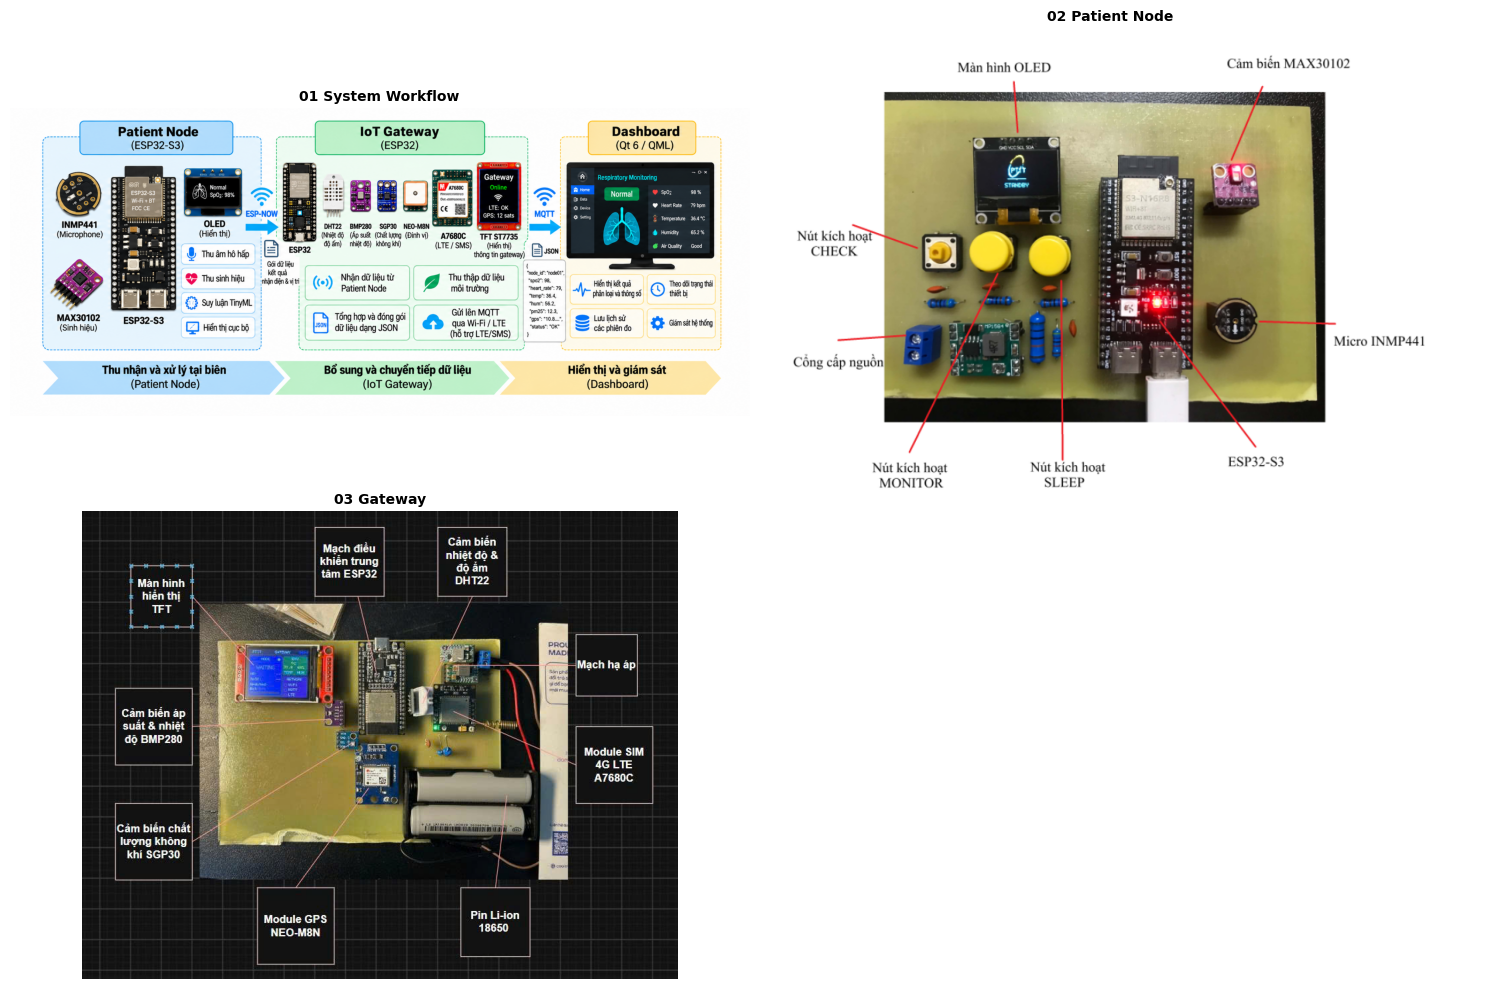

In [23]:
show_images(
    'figures/06_System/01_System_Workflow.png',
    'figures/06_System/02_Patient_Node.png',
    'figures/06_System/03_Gateway.jpg',
    cols=2, figsize=(15, 10),
)